In [1]:
# Libraries Import 

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets,transforms
import matplotlib 
from matplotlib import pyplot as plt

In [2]:
# Preprocessing

transform=transforms.Compose([
    transforms.Resize((28,28)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,),(0.5,))
])


In [3]:
# Load Dataset

train_data = datasets.MNIST(root='./data', train=True, transform=transform, download=True)
test_data = datasets.MNIST(root='./data', train=False, transform=transform)

train_loader = torch.utils.data.DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=64, shuffle=False)

In [4]:
import torch.nn as nn

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.conv1 = nn.Conv2d(1, 32, 3)
        self.conv2 = nn.Conv2d(32, 64, 3)
        
        self.pool = nn.MaxPool2d(2)
        self.relu = nn.ReLU()
        
        self.fc1 = nn.Linear(64*5*5, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        
        x = x.view(x.size(0), -1)   # flatten
        
        x = self.relu(self.fc1(x))  # dense
        x = self.fc2(x)
        
        return x

In [5]:
# model setup

model = CNN()
criterion=nn.CrossEntropyLoss()
optimizer=optim.Adam(model.parameters(), lr=0.001)

In [6]:
# training loop

for epoch in range(5):
    for images, labels in train_loader:
        
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    
    print(f"Epoch {epoch+1}, Loss: {loss.item()}")

Epoch 1, Loss: 0.2080344408750534
Epoch 2, Loss: 0.008535949513316154
Epoch 3, Loss: 0.010303202085196972
Epoch 4, Loss: 0.006332164164632559
Epoch 5, Loss: 0.005313340108841658


In [7]:
# testing accuarcy

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        
        _, predicted = torch.max(outputs, 1)
        
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print("Accuracy:", 100 * correct / total)

Accuracy: 99.24


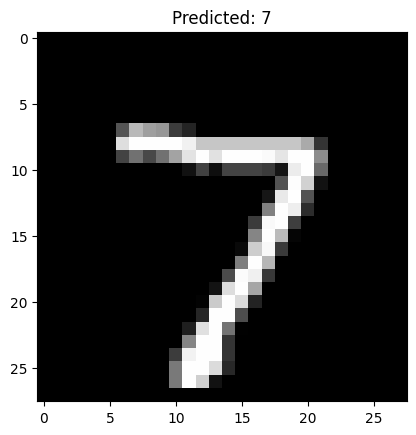

In [8]:
# Visualization Prediction

images, labels = next(iter(test_loader))

outputs = model(images)
_, preds = torch.max(outputs, 1)

plt.imshow(images[0].squeeze(), cmap="gray")
plt.title(f"Predicted: {preds[0].item()}")
plt.show()

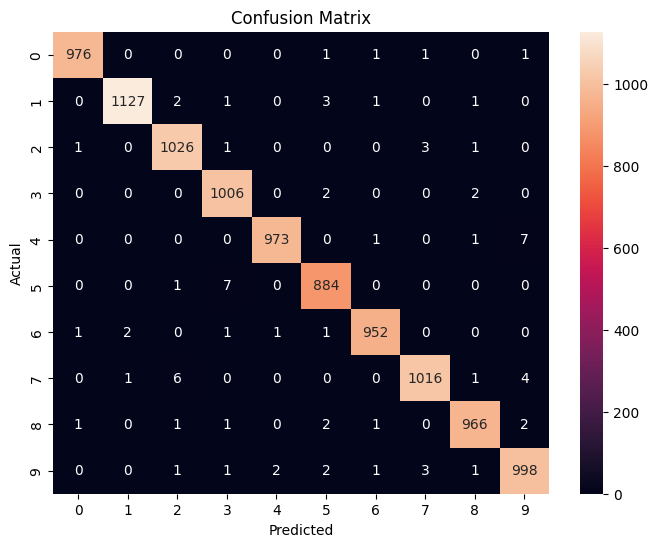

In [9]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        
        all_preds.extend(preds.numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)

# plot
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [10]:
torch.save(model.state_dict(), "mnist_cnn.pth")

In [11]:
model = CNN()
model.load_state_dict(torch.load("mnist_cnn.pth"))
model.eval()

CNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (relu): ReLU()
  (fc1): Linear(in_features=1600, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)